# Baseline: Clinical Model
Before building a more complex model using an image classifier, a simple baseline model will be built and evaluated. This will serve as the benchmark for the MRI scan model to beat. This model will use clinical patient features that came with the metadata. Sex and age are the useable features as they are known at imaging time. Columns like tumor grade and 1p/19q are partly defined by IDH and would be a form of data leakage if included as features.

From `01_metadata_manifest.ipynb`, it was found that age is a very strong indicator of IDH mutation status, so running a logistic regression model with age should yield similar results. Two baseline models will be trained one with just age and another with both age and sex. This is done to see if sex can improve the model or if age is a strong enough feature on its own. `01_metadata_manifest.ipynb` also built the manifest where the 5 patient-level folds were defined and will be used here. 

Probabilites and prediction from the validation folds will be stored and used to evaluate the model (metrics: AUROC, PR-AUC, Brier score, precision, recall, accuracy). Along with a confusion matric, ROC curve, and PR curve, a calibration curve was also plotted. The model is trained without class weights, so its probabilities are centered on the overall mutant rate. A patient is called a mutant when their predicted probability exceeds the mutant rate in the training folds (about 0.28), meaning the model considers them more likely than a typical patient to be a mutant. This rule is fixed from training labels only and is not tuned.

In [1]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (roc_auc_score, average_precision_score, brier_score_loss,
                             accuracy_score, precision_score, recall_score)
from src.cohort import build_cohort


cohort = build_cohort(expected_n=617, verbose=False)
y = cohort["idh"].to_numpy()
folds = cohort["fold"].to_numpy()

# Feature matrix for age and sex (get_dummies convert sex to binary feature)
X_age = cohort[["age"]].astype(float).to_numpy()
X_age_sex_df = pd.get_dummies(cohort[["age", "sex"]], columns=["sex"], drop_first=True, dtype=float)
print(X_age_sex_df.columns.tolist())
X_age_sex = X_age_sex_df.to_numpy()

['age', 'sex_M']


In [2]:
# Train a logistic regression model on each feature set, using the folds in the manifest to do cross-validation. 
# Save the predicted probabilities and 0/1 predictions for each patient in the held-out fold.
models = {"clinical_age": X_age, "clinical_age_sex": X_age_sex}
out_of_fold = {}   # model name -> (predicted probabilities, 0/1 predictions)

for name, X in models.items():
    prob = np.zeros(len(y))                 # one slot per patient, filled in fold by fold
    pred = np.zeros(len(y), dtype=int)      
    for k in np.unique(folds):              # the fold labels saved in the manifest (0 to 4)
        train = folds != k                  # patients in the other four folds
        valid = folds == k                  # patients in the held-out fold
        # The scaler sits inside the pipeline so its mean/std come from the training folds only
        model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
        model.fit(X[train], y[train])       # learn from the four training folds only
        cutoff = y[train].mean()  # the prevalence of mutant in the training folds only (about 0.28)
        prob[valid] = model.predict_proba(X[valid])[:, 1]   # probability of mutant (class 1)
        pred[valid] = (prob[valid] >= cutoff).astype(int)  # 0/1 predictions using the prevalence as cutoff
    out_of_fold[name] = (prob, pred)

In [3]:
# Compute metrics for each model and print them in a table
metrics = {}
for name, (prob, pred) in out_of_fold.items():
    metrics[name] = {"auroc": roc_auc_score(y, prob),
                     "pr_auc": average_precision_score(y, prob),
                     "brier": brier_score_loss(y, prob),
                     "accuracy": accuracy_score(y, pred),
                     "precision": precision_score(y, pred),
                     "recall": recall_score(y, pred),
                     "specificity": recall_score(y, pred, pos_label=0)}

print(pd.DataFrame(metrics).T.round(3))
print("prevalence (PR-AUC baseline):", round(y.mean(), 3), "|Brier of always predicting prevalence:", round(y.mean() * (1 - y.mean()), 3))

                  auroc  pr_auc  brier  accuracy  precision  recall  \
clinical_age       0.88   0.687  0.123     0.818      0.648   0.789   
clinical_age_sex   0.88   0.686  0.123     0.820      0.650   0.794   

                  specificity  
clinical_age             0.83  
clinical_age_sex         0.83  
prevalence (PR-AUC baseline): 0.284 |Brier of always predicting prevalence: 0.203


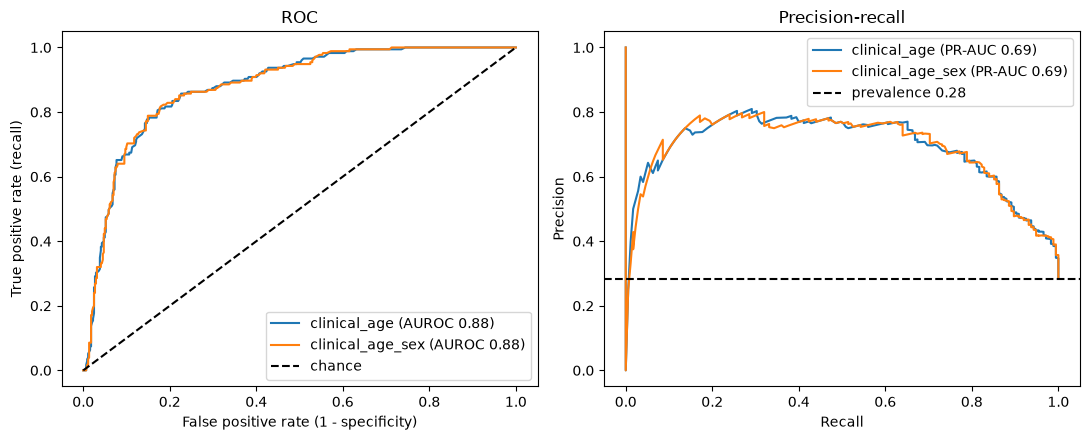

In [4]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, precision_recall_curve, confusion_matrix, ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for name, (prob, pred) in out_of_fold.items():
    fpr, tpr, _ = roc_curve(y, prob)
    (line,) = axes[0].plot(fpr, tpr, label=f"{name} (AUROC {roc_auc_score(y, prob):.2f})")
    prec, rec, _ = precision_recall_curve(y, prob)
    axes[1].plot(rec, prec, label=f"{name} (PR-AUC {average_precision_score(y, prob):.2f})")
axes[0].plot([0, 1], [0, 1], "k--", label="chance")
axes[0].set(xlabel="False positive rate (1 - specificity)", ylabel="True positive rate (recall)", title="ROC")
axes[1].axhline(y.mean(), color="k", ls="--", label=f"prevalence {y.mean():.2f}")
axes[1].set(xlabel="Recall", ylabel="Precision", title="Precision-recall")
for ax in axes:
    ax.legend()
plt.tight_layout()
plt.show()

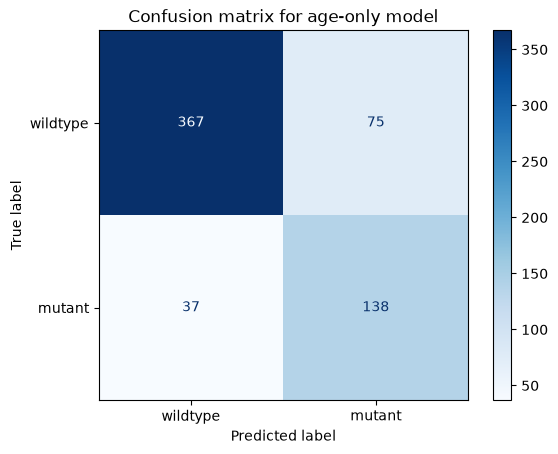

In [5]:
# Confusion matrix for the age-only model at the base-rate cutoff (rows = true, columns = predicted)
_, pred = out_of_fold["clinical_age"]
ConfusionMatrixDisplay(confusion_matrix(y, pred), display_labels=["wildtype", "mutant"]).plot(
    cmap="Blues", values_format="d")
plt.title("Confusion matrix for age-only model")
plt.show()

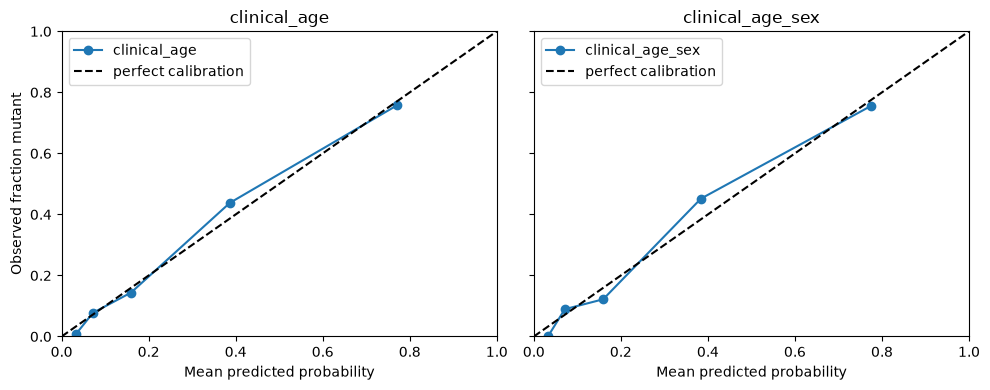

In [6]:
from sklearn.calibration import calibration_curve

fig, axes = plt.subplots(1, len(out_of_fold), figsize=(10, 4), sharex=True, sharey=True)
for ax, (name, (prob, pred)) in zip(axes, out_of_fold.items()):
    # 5 bins with equal numbers of patients, since predictions pile up at low probabilities
    observed, predicted = calibration_curve(y, prob, n_bins=5, strategy="quantile")
    ax.plot(predicted, observed, marker="o", label=name)
    ax.plot([0, 1], [0, 1], "k--", label="perfect calibration")
    ax.set(xlabel="Mean predicted probability", title=name, xlim=(0, 1), ylim=(0, 1))
    ax.legend(loc="upper left")
axes[0].set_ylabel("Observed fraction mutant")
plt.tight_layout()
plt.show()

In [7]:
# Compute per-fold AUROC for the age-only model
fold_auroc = [roc_auc_score(y[folds == k], out_of_fold["clinical_age"][0][folds == k])
              for k in np.unique(folds)]
print("per-fold AUROC:", np.round(fold_auroc, 3),
      "| range", round(min(fold_auroc), 3), "to", round(max(fold_auroc), 3))

per-fold AUROC: [0.859 0.886 0.897 0.837 0.912] | range 0.837 to 0.912


## Bootstrapping Confidence Interval
The AUROC of 0.88 comes from our specific group of 617 patients. A different group of patients would give a slightly different value. To estimate how much it varies, **bootstrapping** was used, essentially the 617 patients were resampled with replacement (so some patients appear more than once and others not at all) to create a new dataset of the same size, recompute AUROC and PR-AUC on it, and repeat this 1000 times. The middle 95% of those 1000 values is the 95% confidence interval. Each patient is a single row, so resampling rows is resampling at the patient level. The interval reflects which patients happened to be in the data, not how the model would change if retrained on different patients. Intervals are computed for AUROC and PR-AUC only.

In [8]:
rng = np.random.default_rng(42)

def bootstrap_ci(y, prob, metric, n_boot=1000):
    n = len(y)
    stats = [metric(y[i], prob[i]) for i in (rng.integers(0, n, n) for _ in range(n_boot))]
    return np.percentile(stats, [2.5, 97.5])

rows = []
for name, (prob, pred) in out_of_fold.items():
    row = {"model": name, "n_patients": len(y), **metrics[name]}
    row["auroc_ci_low"], row["auroc_ci_high"] = bootstrap_ci(y, prob, roc_auc_score)
    row["pr_auc_ci_low"], row["pr_auc_ci_high"] = bootstrap_ci(y, prob, average_precision_score)
    rows.append(row)
comparison = pd.DataFrame(rows).round(3)

summary = pd.DataFrame({
    "AUROC (95% CI)": [f"{r.auroc:.2f} ({r.auroc_ci_low:.2f} to {r.auroc_ci_high:.2f})"
                       for r in comparison.itertuples()],
    "PR-AUC (95% CI)": [f"{r.pr_auc:.2f} ({r.pr_auc_ci_low:.2f} to {r.pr_auc_ci_high:.2f})"
                        for r in comparison.itertuples()],
}, index=comparison["model"])

print(summary, "\n")
print("Other Metrics (no confidence intervals):")
print(comparison.set_index("model")[["accuracy", "precision", "recall", "specificity", "brier"]].round(3))

                       AUROC (95% CI)      PR-AUC (95% CI)
model                                                     
clinical_age      0.88 (0.85 to 0.91)  0.69 (0.62 to 0.77)
clinical_age_sex  0.88 (0.85 to 0.91)  0.69 (0.61 to 0.77) 

Other Metrics (no confidence intervals):
                  accuracy  precision  recall  specificity  brier
model                                                            
clinical_age         0.818      0.648   0.789         0.83  0.123
clinical_age_sex     0.820      0.650   0.794         0.83  0.123


## Takeaways
At the base-rate cutoff it catches 138 of 175 mutants (recall 0.79), but 75 of the 213 patients it calls mutant are wildtype (precision 0.65). This is the bar the image model must clear. The Brier score is 0.123, compared with 0.203 for a model that predicts the overall mutant rate for all samples, and the calibration curve stays close to the diagonal, so on UTSW the predicted probabilities roughly match observed mutant rates. Deviations in individual bins are within what 5 bins of about 123 patients would produce by chance. This is internal calibration only. The curve will be checked again on UCSF without any recalibration.

**Reading the Intervals:**
The AUROC of 0.88 has a 95% confidence interval of 0.85 to 0.91, so the true value for patients like these plausibly lies in that range. If the whole study were repeated on new samples, about 95% of intervals built this way would contain the true AUROC. Most importantly, this interval sets the bar for later comparisons: a model scoring 0.89 or 0.90 can’t be called better than this baseline from the intervals alone. The age-only and age+sex intervals overlap almost completely, so sex adds nothing measurable. The PR-AUC interval is wider because there are only 175 mutant patients.

**Limitations:** These are internal cross-validation results from one institution, not external validation. The CIs reflect patient sampling only.

## Save Results
Saved as csv files so that results can be compared to other models. 

In [9]:
from src.config import LOG
RESULTS = LOG.parent                     # the results/ folder
KEY = ["patient_id", "fold", "idh"]

# 1) Per-patient out-of-fold probabilities, one column per model
new = pd.DataFrame({"patient_id": cohort["patient_id"], "fold": folds, "idh": y,
                    **{f"{name}_prob": out_of_fold[name][0] for name in out_of_fold}})
oof_path = RESULTS / "oof_predictions.csv"
if oof_path.exists():
    old = pd.read_csv(oof_path).drop(columns=[c for c in new.columns if c not in KEY], errors="ignore")
    new = old.merge(new, on=KEY, how="outer")
new.to_csv(oof_path, index=False)

# 2) Summary metrics, one row per model
cmp_path = RESULTS / "model_comparison.csv"
if cmp_path.exists():
    old = pd.read_csv(cmp_path)
    comparison = pd.concat([old[~old["model"].isin(comparison["model"])], comparison], ignore_index=True)
comparison.to_csv(cmp_path, index=False)